In [29]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
import matplotlib.pyplot as plt
from sklearn.model_selection import KFold

In [30]:
df = pd.read_csv('https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv')

#Data preparation
df.columns = df.columns.str.lower().str.replace(' ', '_')
categorical_columns = list(df.select_dtypes(include=['object', 'str']).columns) #added 'str' because otherwise it returned []
numerical_columns = list(df.select_dtypes(include='number').columns) #had to look select_dtypes up
for c in categorical_columns:
    df[c] = df[c].str.strip().str.lower().str.replace(' ', '_')
    df[c] = df[c].replace('', np.nan)

df[categorical_columns] = df[categorical_columns].fillna('NA')
df[numerical_columns] = df[numerical_columns].fillna(0.0)

df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train.converted.values
y_val = df_val.converted.values
y_test = df_test.converted.values

del df_train['converted']
del df_val['converted']
del df_test['converted']

In [31]:
#Q1
numerical_columns = ['annual_income', 'number_of_courses_viewed','interaction_count','lead_score',] #So 'converted' it's not in the list

for c in numerical_columns:
    auc = roc_auc_score(y_train, df_train[c])
    if auc < 0.5:
        auc = roc_auc_score(y_train, -df_train[c])
    print(c, auc)

annual_income 0.6081977776250831
number_of_courses_viewed 0.7229894623989618
interaction_count 0.7649203047563227
lead_score 0.7882254810906102


In [32]:
#Q2
dv = DictVectorizer(sparse=False)
train_dict = df_train[categorical_columns + numerical_columns].to_dict(orient='records')
X_train = dv.fit_transform(train_dict)
val_dict = df_val[categorical_columns + numerical_columns].to_dict(orient='records')
X_val = dv.transform(val_dict)

model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)

y_pred = model.predict_proba(X_val)[:, 1]
auc = roc_auc_score(y_val, y_pred)
print(round(auc,3))

0.732


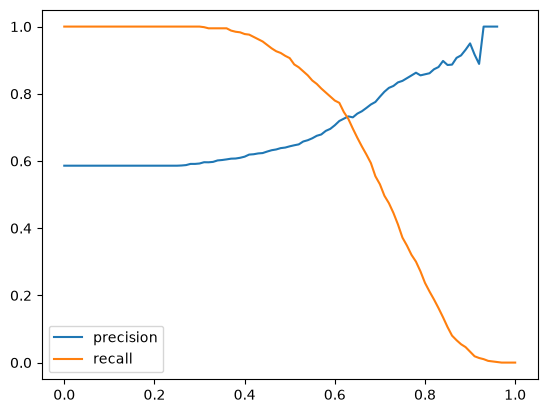

In [33]:
#Q3
scores = []
thresholds = np.linspace(0, 1, 101)
for t in thresholds:
    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)
    
    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)

    tp = (predict_positive & actual_positive).sum()
    tn = (predict_negative & actual_negative).sum()

    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()
    
    scores.append((t, tp, fp, fn, tn))

columns = ['threshold', 'tp', 'fp', 'fn', 'tn']
df_scores = pd.DataFrame(scores, columns=columns)

df_scores['precision'] = df_scores.tp / (df_scores.tp + df_scores.fp)
df_scores['recall'] = df_scores.tp / (df_scores.tp + df_scores.fn)

plt.plot(df_scores.threshold, df_scores['precision'], label='precision')
plt.plot(df_scores.threshold, df_scores['recall'], label='recall')
plt.legend()

In [34]:
#Q4
df_scores['f1'] = 2 * (df_scores['precision'] * df_scores['recall']) / (df_scores['precision'] + df_scores['recall'])
df_scores['f1'] = df_scores['f1'].fillna(0)
df_scores.loc[df_scores['f1'].idxmax(), ['threshold', 'f1']]

threshold    0.410000
f1           0.757616
Name: 41, dtype: float64

In [35]:
#Q5
kfold = KFold(n_splits=5, shuffle=True, random_state=1)
scores = []
for train_idx, val_idx in kfold.split(df_full_train):
    df_train = df_full_train.iloc[train_idx]
    df_val = df_full_train.iloc[val_idx]

    y_train = df_train.converted.values
    y_val = df_val.converted.values

    del df_train['converted']
    del df_val['converted']

    dv = DictVectorizer(sparse=False)
    train_dict = df_train.to_dict(orient='records')
    X_train = dv.fit_transform(train_dict)

    val_dict = df_val.to_dict(orient='records')
    X_val = dv.transform(val_dict)

    model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
    model.fit(X_train, y_train)

    y_pred = model.predict_proba(X_val)[:, 1]
    auc = roc_auc_score(y_val, y_pred)

    scores.append(auc)

print("AUC scores:", scores)
print("Deviation:", np.std(scores))
print()

AUC scores: [0.7305601027122453, 0.7295726148196622, 0.7363428071259397, 0.7412454717957564, 0.7209138590326581]
Deviation: 0.006853233151022138



In [36]:
#Q6
for C in [0.000001, 0.001, 1]:
    scores = []
    for train_idx, val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx].copy()
        df_val = df_full_train.iloc[val_idx].copy()
    
        y_train = df_train.converted.values
        y_val = df_val.converted.values
    
        del df_train['converted']
        del df_val['converted']
    
        dv = DictVectorizer(sparse=False)
        train_dict = df_train.to_dict(orient='records')
        X_train = dv.fit_transform(train_dict)
    
        val_dict = df_val.to_dict(orient='records')
        X_val = dv.transform(val_dict)
    
        model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
        model.fit(X_train, y_train)
    
        y_pred = model.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred)
    
        scores.append(auc)

        print(f"C={C}: mean={np.mean(scores):.3f}", f"std={np.std(scores):.3f}")

C=1e-06: mean=0.594 std=0.000
C=1e-06: mean=0.617 std=0.023
C=1e-06: mean=0.611 std=0.020
C=1e-06: mean=0.618 std=0.021
C=1e-06: mean=0.617 std=0.019
C=0.001: mean=0.750 std=0.000
C=0.001: mean=0.749 std=0.001
C=0.001: mean=0.752 std=0.005
C=0.001: mean=0.754 std=0.005
C=0.001: mean=0.749 std=0.010
C=1: mean=0.731 std=0.000
C=1: mean=0.730 std=0.000
C=1: mean=0.732 std=0.003
C=1: mean=0.734 std=0.005
C=1: mean=0.732 std=0.007
